This script is to calculate whether unitaries generated by a specific hamiltonian can be transposed by 1-slot comb 
deterministically and exactly, whose gates are all pauli gates.

Usage:
   - Parameters for run_search:

       `PAULI_SUPPORTS` : List of Hamiltonian Pauli term supports

In [ ]:
from typing import List

import quairkit as qk
import torch

from utils.hamiltonian_utils import (HamiltonianPQCombNet,
                               generate_v_transpose_param_circuits,
                               get_num_qubits_from_pauli_support)
from quairkit.database import zero_state

In [37]:
# qk.set_device('cuda')
qk.set_dtype("complex128")

In [38]:
def transpose(unitary: torch.Tensor) -> torch.Tensor:
    return unitary.transpose(-2, -1).contiguous()

In [ ]:
PAULI_SUPPORT: List[str] = ['Y0', 'Y1', 'Y0,Y1']

First V transpose parameter circuit:


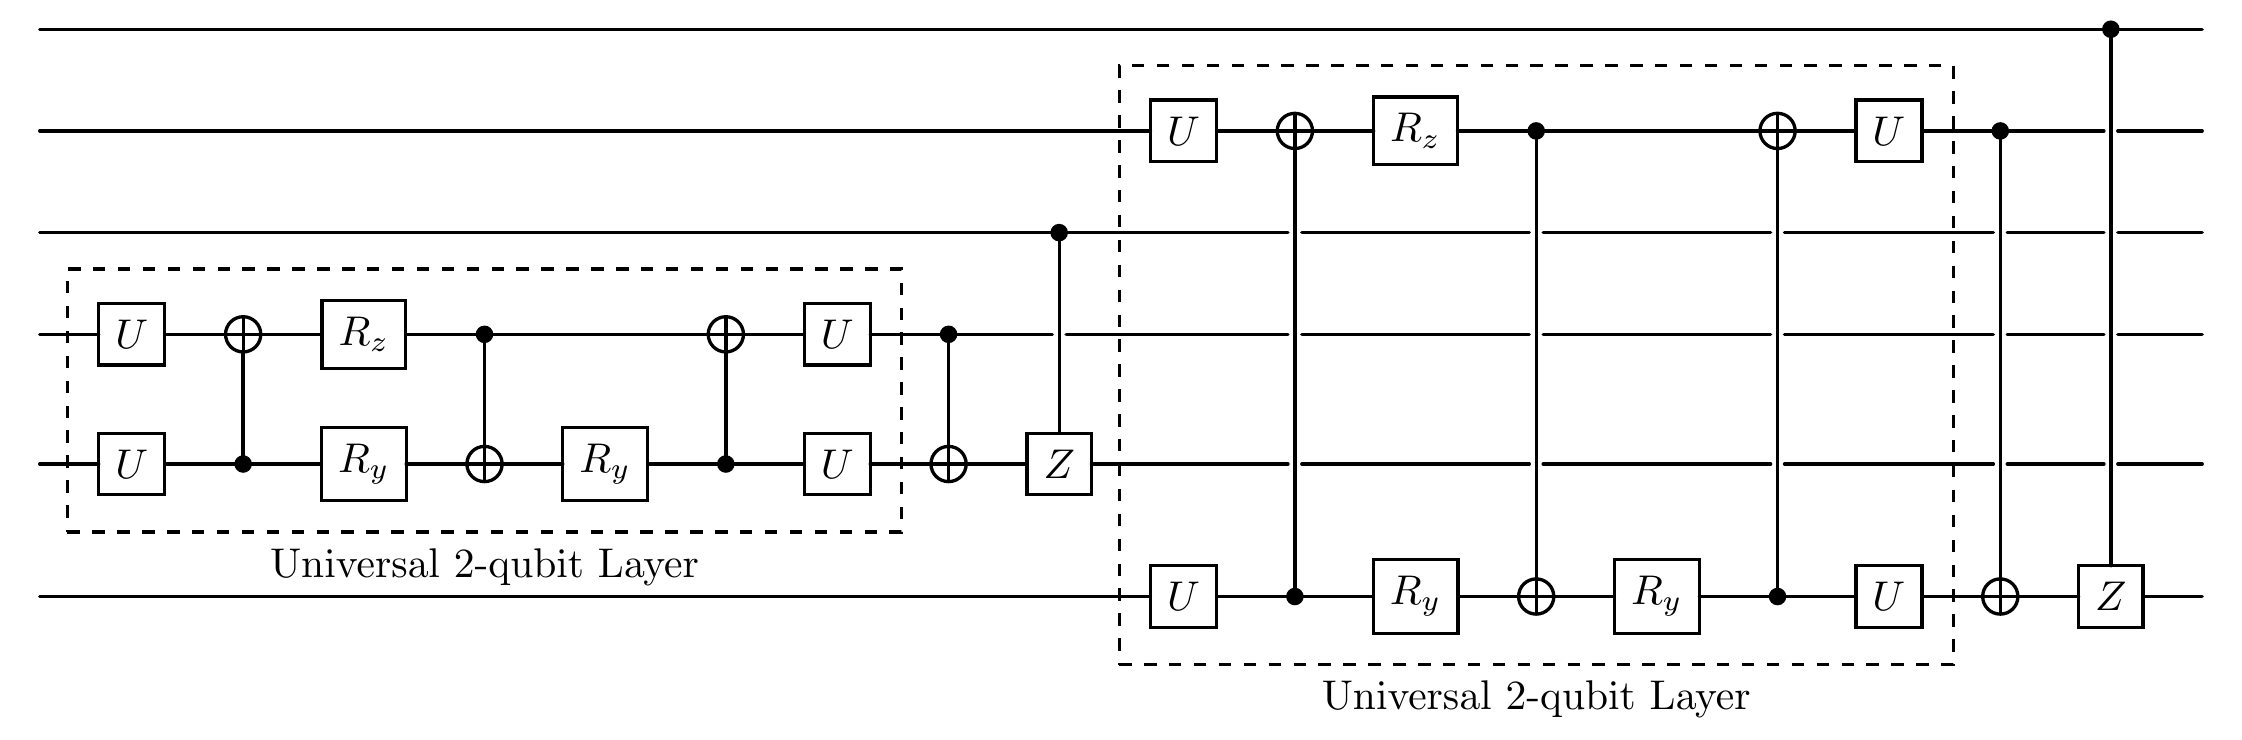

Second V transpose parameter circuit:


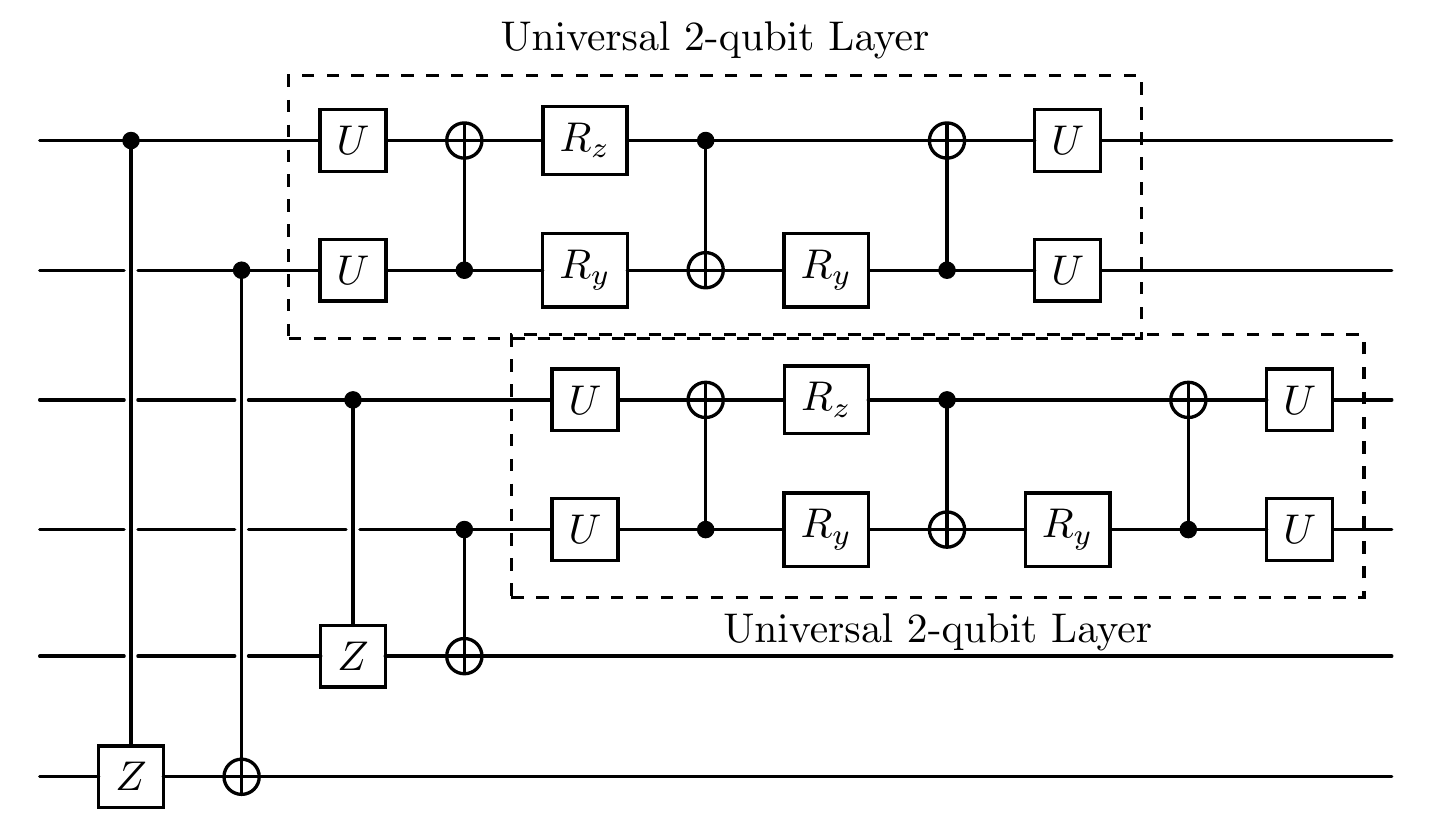

In [ ]:
num_qubits = get_num_qubits_from_pauli_support(PAULI_SUPPORT)
v_transpose_param_cir = generate_v_transpose_param_circuits(num_qubits)
# Print the first V transpose parameter circuit description
print("First V transpose parameter circuit:")
# Plot the first circuit in v_transpose_param_cir
v_transpose_param_cir[0].plot('compact')
print("Second V transpose parameter circuit:")
# Plot the second circuit in v_transpose_param_cir
v_transpose_param_cir[1].plot('compact')

In [41]:
net = HamiltonianPQCombNet(
    target_func=transpose,
    task_name="search_U_transpose_param",
    v_circuits=v_transpose_param_cir,
)

In [ ]:
result = net.search_from_list(
    pauli_supports=[PAULI_SUPPORT],
    slots=1,
    parallel=1,
    ancilla=2 * num_qubits,
    projector=zero_state(2 * num_qubits).density_matrix,
    # verbose=True,
)


[LIST SEARCH] Starting search from 1 predefined Hamiltonian operator lists


[LIST SEARCH] Processing lists:   0%|          | 0/1 [00:00<?, ?it/s]


[LIST SEARCH] Processing list 1/1
[LIST SEARCH] Operators: ['Y0', 'Y1', 'Y0,Y1']

[SEARCH CONFIG] Starting search for Hamiltonian operators: ['Y0', 'Y1', 'Y0,Y1']
[SEARCH CONFIG] Slots parameter: 1, Parallel parameter: 1
[SEARCH CONFIG] Testing 1 different configurations: [(1, 4, 1)]
[SEARCH CONFIG] Computed qubits: 2
[SEARCH CONFIG] Generated training set size: 1000, test set size: 1000



[SEARCH CONFIG] Testing configuration 1/1: slots=1, parallel=1

[SEARCH] Testing configuration: slots=1, parallel=1, ancilla=4
[SEARCH] Hamiltonian operators: ['Y0', 'Y1', 'Y0,Y1']
[SEARCH] Number of qubits: 2


[SEARCH] Attempt 1/50...


[LIST SEARCH] Processing lists: 100%|██████████| 1/1 [00:16<00:00, 16.17s/it]

[SEARCH] Attempt 1 fidelity: 0.999996
[SEARCH] New best fidelity: 0.999996, new best prob_success: 0.998924
[SEARCH] Success! Fidelity 0.999996 exceeds threshold 0.999
[SEARCH CONFIG] New best configuration: slots=1, parallel=1, ancilla=4, fidelity=0.999996
[SEARCH CONFIG] Found satisfactory configuration with fidelity 0.999996
[SEARCH] Attempting to save result to: /home/tx/QuAIR/EfficientUnitaryInversion/results/search_U_transpose_param/from_list.csv
[SEARCH] File already exists: True
[SEARCH] Appending to existing file
[SEARCH] Successfully saved result to /home/tx/QuAIR/EfficientUnitaryInversion/results/search_U_transpose_param/from_list.csv
[LIST SEARCH] List 1 completed with fidelity: 0.999996

[LIST SEARCH] All 1 lists completed. Valid results saved to from_list.csv


In [ ]:
for res in result:
    num_slots = res['num_slots']
    num_parallels = res['num_parallels']
    ancilla = res['ancilla']
    prob_success = res['prob_success']
    PAULI_SUPPORT = res['pauli_support']
    if num_slots > 0 and num_parallels > 0 and ancilla >= 0 and prob_success > 0.999:
        print(
            f"Unitary matrices from {PAULI_SUPPORT} can be implemented "
            f"with probability {prob_success:.6f} "
            f"for {net.target_func.__name__} with "
            f"Fidelity: {res['fidelity']:.6f} and Success Probability: {res['prob_success']:.6f}"
        )
    else:
        print(
            f"Unitary matrices from {PAULI_SUPPORT} cannot be implemented deterministically and exactly "
            f"for {net.target_func.__name__} with the specified slots, parallels, and ancilla qubits."
        )

Unitarias from ['Y0', 'Y1', 'Y0,Y1'] cannot be implemented deterministically and exactly for transpose with the specified slots, parallels, and ancilla qubits.


First V transpose parameter circuit:


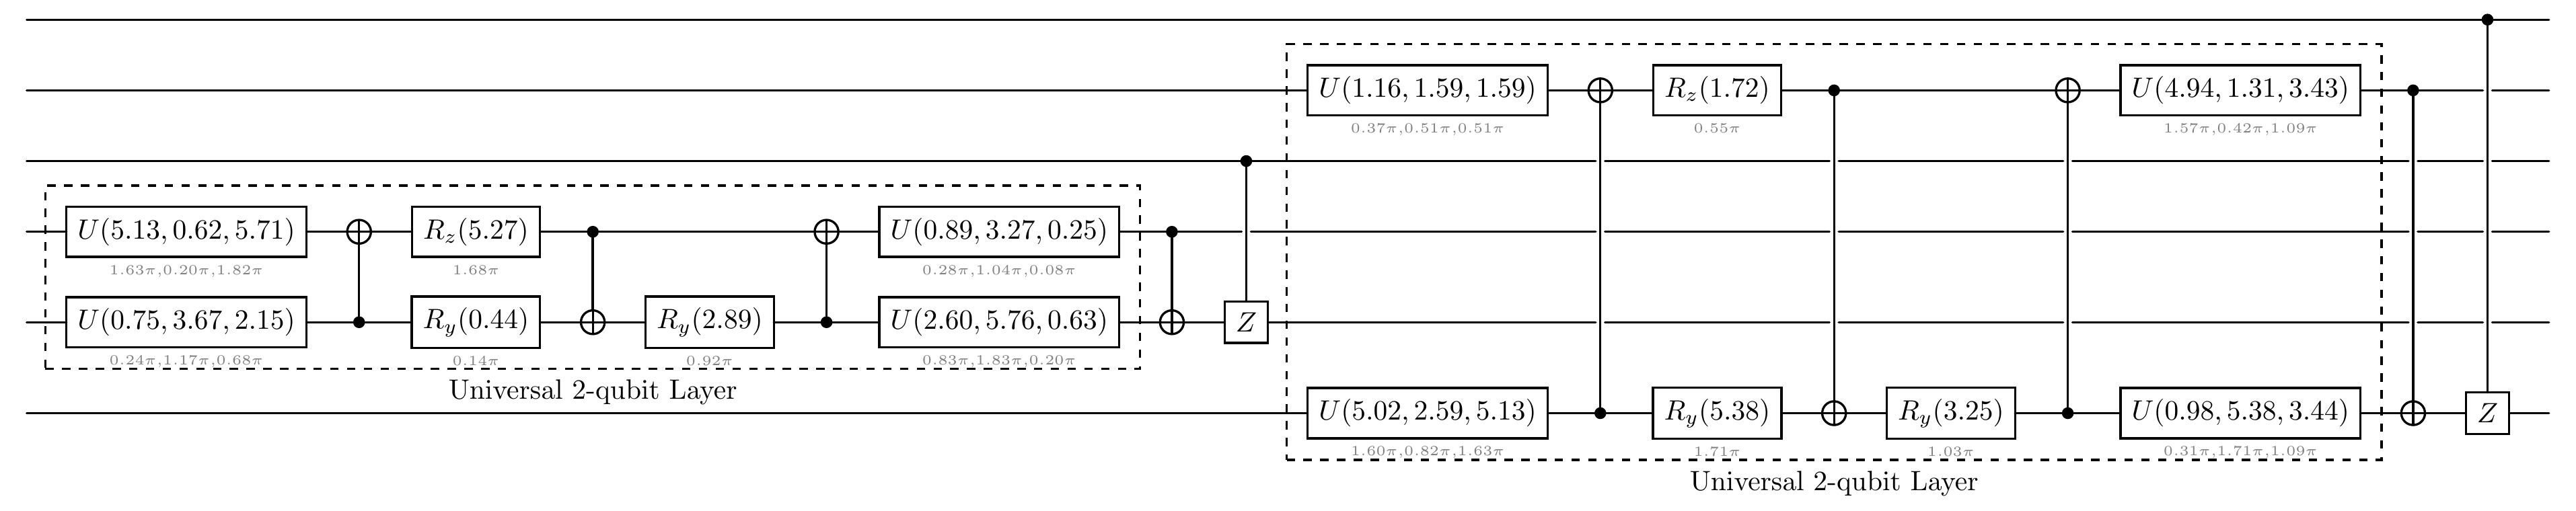

Second V transpose parameter circuit:


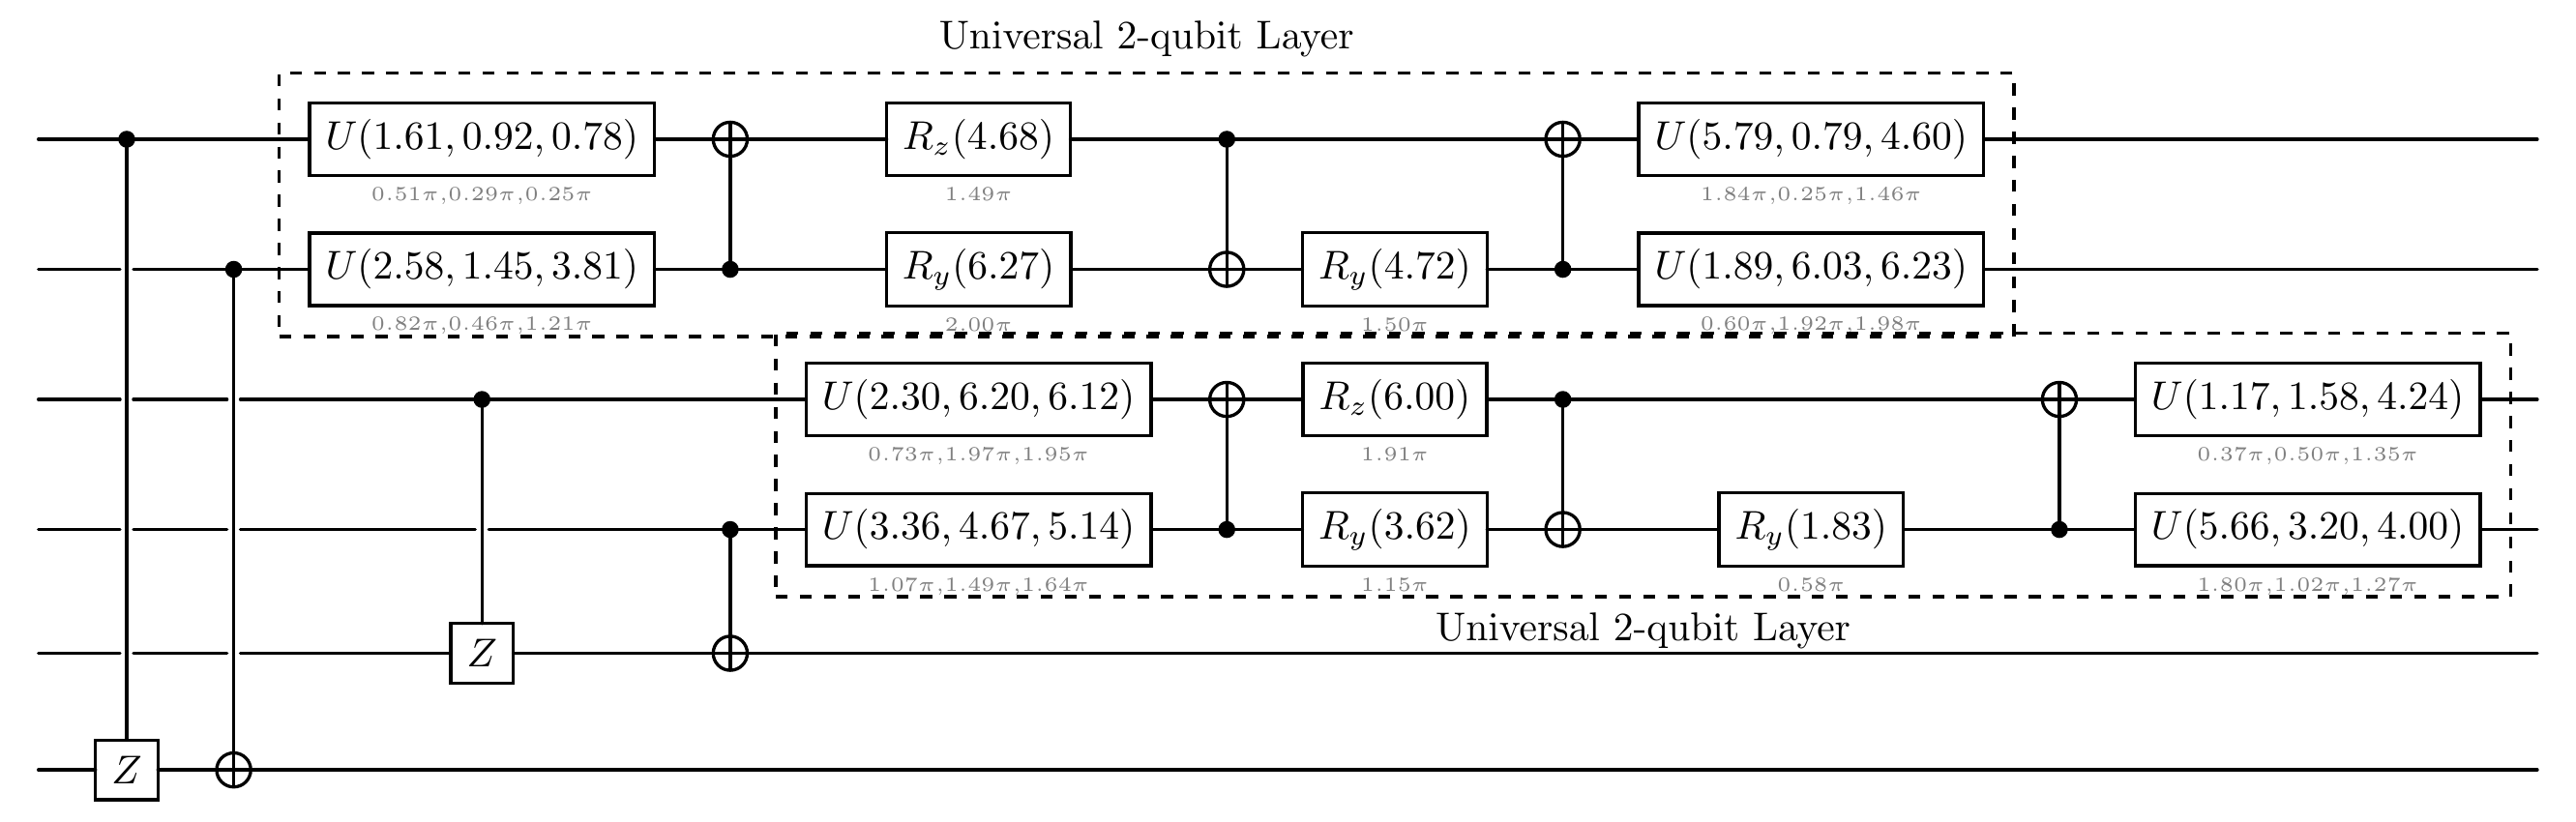

In [ ]:
num_qubits = get_num_qubits_from_pauli_support(PAULI_SUPPORT)
v_transpose_param_cir = generate_v_transpose_param_circuits(num_qubits)
# Print the first V transpose parameter circuit description
print("First V transpose parameter circuit:")
# Plot the first circuit in v_transpose_param_cir
v_transpose_param_cir[0].plot('detailed')
print("Second V transpose parameter circuit:")
# Plot the second circuit in v_transpose_param_cir
v_transpose_param_cir[1].plot('detailed')